In [1]:
Pkg.instantiate()
Pkg.resolve()

  No Changes to `~/.julia/v1.11/Project.toml`
  No Changes to `~/.julia/v1.11/Manifest.toml`


In [2]:
# Pkg.add("Turing")
# Pkg.add("Capse")
# Pkg.add("NPZ")
# Pkg.add(url="https://github.com/JuliaCosmologicalLikelihoods/PlanckLite.jl")
# Pkg.add("BenchmarkTools")
# Pkg.add("Plots")
# Pkg.add("Optim")
# Pkg.add("ForwardDiff")
# Pkg.add("LinearAlgebra")
# Pkg.add("Pathfinder")
# Pkg.add("MicroCanonicalHMC")
# Pkg.add("Transducers")
# Pkg.add("StatsPlots")
# Pkg.add("PairPlots")
# Pkg.add("LaTeXStrings")
# Pkg.add("MCMCChains")
# Pkg.add("PSIS")
# Pkg.add("ArviZ")
# Pkg.add("ArviZPythonPlots")
# Pkg.add("IrrationalConstants")
# Pkg.add("DimensionalData")
# Pkg.add("Statistics")

In [3]:
# using Turing
# using Capse
using NPZ
# # using PlanckLite
# using BenchmarkTools
# using Plots
# using Optim
# using ForwardDiff
# using Pathfinder
# #using MicroCanonicalHMC
# #using Transducers
# using StatsPlots
# #using PairPlots
# #using LaTeXStrings
# #using CairoMakie
# using MCMCChains
using PSIS
# include("utils.jl");
using ArviZ
using ArviZPythonPlots
using LinearAlgebra
using IrrationalConstants
using DimensionalData
using Statistics
using Plots

### PSIS

Begin by running Pareto Smoothed Importance Sampling (PSIS) on the full voxels, and storing the results.

In [7]:
f = npzread("/Users/ethansmith/Desktop/Waterloo/Masters/LOO-PIT/loop_it_in_the_field/data_hugo/fixed_ic/logdf_mesh.npz")

Dict{String, Array{Float64, 5}} with 2 entries:
  "logcdf_mesh" => [-0.422306 -0.432131 … -0.41779 -0.429081; -0.428338 -0.4283…
  "logpdf_mesh" => [-3.66273 -3.65593 … -3.66599 -3.658; -3.65851 -3.65847 … -3…

For the process of PSIS, we need the delta_logdensity field, which are the log density probabilities that the chain has determined by fitting the model to the full data set. That is, the delta_logdensity represent $p(\theta | y)$.

In [8]:
f["logpdf_mesh"]

4×512×32×32×32 Array{Float64, 5}:
[:, :, 1, 1, 1] =
 -3.66273  -3.65593  -3.65958  -3.66154  …  -3.65461  -3.66599  -3.658
 -3.65851  -3.65847  -3.65608  -3.66237     -3.66681  -3.66477  -3.65942
 -3.66151  -3.65806  -3.66311  -3.65798     -3.65623  -3.65636  -3.66537
 -3.65984  -3.6677   -3.6602   -3.66124     -3.65894  -3.66515  -3.66617

[:, :, 2, 1, 1] =
 -3.5853   -3.58419  -3.58473  -3.5849   …  -3.58398  -3.58606  -3.58427
 -3.58441  -3.58458  -3.58407  -3.58544     -3.58595  -3.5854   -3.58462
 -3.58493  -3.58427  -3.58529  -3.58425     -3.58409  -3.58414  -3.58604
 -3.58479  -3.58581  -3.58466  -3.58488     -3.58461  -3.58561  -3.58598

[:, :, 3, 1, 1] =
 -3.84162  -3.83027  -3.83761  -3.84832  …  -3.82973  -3.84179  -3.84578
 -3.84308  -3.83449  -3.83847  -3.8327      -3.85314  -3.85658  -3.84145
 -3.84652  -3.84641  -3.84558  -3.84685     -3.83904  -3.83739  -3.83683
 -3.83735  -3.86705  -3.84697  -3.84644     -3.83726  -3.85148  -3.84644

;;; … 

[:, :, 30, 1, 1] =
 -3.7085

Each of the 32 x 32 x 32 voxels has 4 x 512 delta logdensities from the chain corresponding to that voxel. Each file represents a section of the chain that was saved as a checkpoint, and so all of the files together form the full data set.

Below, we create a vector called full_voxel_data to store the data from all of the files, reading each in sequence and appending the delta_logdensity values to the data object.

In [9]:
full_voxel_data = Array{Vector{Float64}}(undef, 32, 32, 32)

for i in 1:32, j in 1:32, k in 1:32
    full_voxel_data[i,j,k] = []
end

In [10]:
# for file in 1:7

#     x = npzread("/Users/ethansmith/Desktop/Waterloo/Masters/LOO-PIT/loop_it_in_the_field/lpt_32_eh1_ovsamp1/test_with_delta_logdensity_$(file).npz")
#     delta_logdensities = x["delta_logdensity"]

#     for i in 1:32, j in 1:32, k in 1:32
#         append!(full_voxel_data[i, j, k], vec(delta_logdensities[:, :, i, j, k]))
#     end

# end

for i in 1:32, j in 1:32, k in 1:32
    append!(full_voxel_data[i,j,k], vec(f["logpdf_mesh"][:,:,i,j,k]))
end

Thus, full_voxel_data is a data object representing the 32 x 32 x 32 voxels, with each element holding 7168 delta_logdensity values collected from across the all of the files. 

In [11]:
full_voxel_data

32×32×32 Array{Vector{Float64}, 3}:
[:, :, 1] =
 [-3.66273, -3.65851, -3.66151, -3.65984, -3.65593, -3.65847, -3.65806, -3.6677, -3.65958, -3.65608  …  -3.65623, -3.65894, -3.66599, -3.66477, -3.65636, -3.66515, -3.658, -3.65942, -3.66537, -3.66617]     …  [-3.84296, -3.83876, -3.84301, -3.83861, -3.83232, -3.8363, -3.8392, -3.85543, -3.8384, -3.83479  …  -3.83512, -3.83761, -3.84651, -3.84936, -3.8348, -3.84835, -3.83895, -3.83931, -3.84444, -3.84802]
 [-3.5853, -3.58441, -3.58493, -3.58479, -3.58419, -3.58458, -3.58427, -3.58581, -3.58473, -3.58407  …  -3.58409, -3.58461, -3.58606, -3.5854, -3.58414, -3.58561, -3.58427, -3.58462, -3.58604, -3.58598]       [-3.62951, -3.63081, -3.63172, -3.62824, -3.62602, -3.62731, -3.63226, -3.63932, -3.62839, -3.62932  …  -3.62953, -3.62835, -3.62905, -3.63537, -3.62883, -3.63317, -3.63201, -3.62998, -3.62715, -3.63092]
 [-3.84162, -3.84308, -3.84652, -3.83735, -3.83027, -3.83449, -3.84641, -3.86705, -3.83761, -3.83847  …  -3.83904, -3.83726, -3.84

In [12]:
full_voxel_data[3,16,4]

2048-element Vector{Float64}:
 -4.565168857605628
 -4.558729988483616
 -4.559683635492516
 -4.5650916656926235
 -4.566006772012023
 -4.565723117497284
 -4.555478010316706
 -4.5509520817992
 -4.564547871722637
 -4.559418892974969
 -4.562415705304059
 -4.557708926945701
 -4.558276181985038
  ⋮
 -4.5647591731627895
 -4.560815560828795
 -4.559143550168367
 -4.5640321306907605
 -4.569000642415665
 -4.5556355294572475
 -4.560665402698266
 -4.560145552712189
 -4.5559059114109655
 -4.561198984431772
 -4.572333541443412
 -4.565435718436226

Next, perform Pareto Smoothed Importance Sampling (PSIS) on each voxel's vector of delta logdensities.

In [13]:
psis_result = Array{PSISResult{Float64, Vector{Float64}, Int64, Int64, PSIS.GeneralizedPareto{Float64}}}(undef, 32, 32, 32);
for i in 1:32, j in 1:32, k in 1:32
    psis_result[i, j, k] = psis(full_voxel_data[i,j,k])
end

Store the weights and the pareto shape values in their own 32 x 32 x 32 arrays so that the PSIS weights and the pareto shape value can be recalled easily for each voxel if needed.

In [14]:
psis_weights = Array{Vector{Float64}}(undef, 32, 32, 32)
for i in 1:32, j in 1:32, k in 1:32
    psis_weights[i,j,k] = psis_result[i,j,k].weights
end

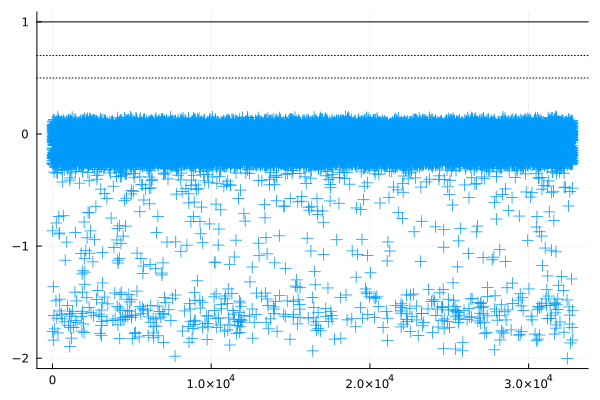

In [15]:
pareto_shapes = []
for i in 1:32, j in 1:32, k in 1:32
    append!(pareto_shapes, psis_result[i,j,k].pareto_shape)
end

psis_plot = Plots.scatter(pareto_shapes; marker =:+, markersize=6, legend = false, linewidth=2)
hline!([0.5,0.7], linestyle=:dot, color =:black)
hline!([1.0], linestyle=:solid, color=:black)

We now use the data to generate an Inference Data object that stores the log probabilities

In [16]:
idata = InferenceData(; log_probabilities=namedtuple_to_dataset((; D=full_voxel_data)))

InferenceData with groups:
  > log_probabilities

In [17]:
idata.log_probabilities[5,2,17][:D]

2048-element Vector{Float64}:
 -3.5850929974065004
 -3.5851936394306447
 -3.584896827856284
 -3.5854428682250448
 -3.5860401460620857
 -3.585666155680844
 -3.5850422567521463
 -3.5838384146207543
 -3.585440098535994
 -3.585551281300058
 -3.5848795344501436
 -3.584926992336091
 -3.584809294690106
  ⋮
 -3.5861406848425177
 -3.584400505728236
 -3.5855124620850716
 -3.585487821968094
 -3.5849541963105516
 -3.5843250762485446
 -3.5855990665418
 -3.5845303114536327
 -3.585076654539262
 -3.585240248691263
 -3.585234021413219
 -3.584722909322886

Let us now upload the µ values that were set by the MCMC run, provided by Hugo Simon and Arnaud de Mattia.

In [18]:
x = npzread("/Users/ethansmith/Desktop/Waterloo/Masters/LOO-PIT/loop_it_in_the_field/lpt_32_eh1_ovsamp1/test_with_delta_logdensity_mean_var_1.npz")

Dict{String, Array{Float64}} with 14 entries:
  "sigma_delta_"     => [-5.54569 -8.14349 … -3.08195 -3.21208; -3.24658 -3.545…
  "delta_logdensity" => [4.07328 4.00311 … 3.936 4.09871; 4.04975 4.4579 … 3.98…
  "bs2_"             => [5.90593 2.63669 … 3.05455 2.20421; 4.35411 6.40152 … 4…
  "field_mean"       => [140.825 128.745 … 137.146 143.79; 144.137 111.356 … 13…
  "n_evals"          => [128.0 128.0 … 128.0 128.0; 128.0 128.0 … 128.0 128.0; …
  "sigma_0_"         => [7.32838 6.68079 … 5.49941 6.16135; 3.60744 5.13712 … 4…
  "ngbars_"          => [-0.573705 -0.638882 … 0.108464 -0.005616; -0.364082 -0…
  "logdensity"       => [-2.44378e5 -2.44289e5 … -2.42482e5 -2.43582e5; -2.4005…
  "init_mesh_"       => [-2.39885 0.911602 … -1.17294 1.04165; 0.20935 -2.12978…
  "b1_"              => [1.48338 1.22232 … 1.79489 1.06108; 2.17415 1.5503 … 1.…
  "field_var"        => [466.571 466.021 … 391.101 416.116; 343.781 366.364 … 4…
  "b2_"              => [0.793201 1.05119 … 0.304136 0.0286908;

Once again the file contains many fields. We are primarily concerned with the "field_mean" that is represented as a pseudo-count of galaxies in the voxel.

We iterate over all of the files to create a single 32 x 32 x 32 array of voxels where each data element is a vector representing the sampled µ values of that voxel.

In [22]:
full_mean_data = Array{Vector{Float64}}(undef, 32, 32, 32)

for i in 1:32, j in 1:32, k in 1:32
    full_mean_data[i,j,k] = []
end

for file in 1:2

    x = npzread("/Users/ethansmith/Desktop/Waterloo/Masters/LOO-PIT/loop_it_in_the_field/lpt_32_eh1_ovsamp1/test_with_delta_logdensity_mean_var_$(file).npz")
    field_mean = x["field_mean"]

    for i in 1:32, j in 1:32, k in 1:32
        append!(full_mean_data[i, j, k], vec(field_mean[:, :, i, j, k]))
    end
    
end

In [23]:
full_mean_data

32×32×32 Array{Vector{Float64}, 3}:
[:, :, 1] =
 [140.825, 144.137, 147.685, 117.396, 128.745, 111.356, 125.13, 98.6394, 152.855, 101.584  …  163.781, 121.412, 132.906, 118.398, 160.269, 144.254, 130.423, 124.195, 147.205, 151.878]   …  [127.192, 139.406, 122.697, 123.306, 158.652, 84.7303, 123.866, 95.1005, 131.876, 81.2327  …  138.618, 115.241, 133.576, 127.053, 136.014, 81.8637, 135.426, 109.84, 156.514, 111.056]
 [123.796, 120.239, 118.567, 92.4224, 123.832, 114.444, 127.105, 114.7, 103.345, 132.177  …  98.0111, 98.0053, 158.69, 115.465, 96.8271, 117.441, 132.021, 105.139, 122.603, 103.704]        [260.737, 270.912, 248.897, 274.453, 238.076, 264.934, 276.968, 250.432, 252.61, 258.94  …  259.118, 272.045, 244.462, 272.651, 269.221, 274.904, 248.516, 236.033, 277.747, 291.028]
 [290.599, 296.207, 307.613, 331.991, 285.735, 299.078, 318.945, 302.666, 269.45, 276.391  …  283.009, 268.345, 256.948, 292.208, 301.264, 296.396, 268.82, 261.141, 320.146, 307.655]       [240.626, 237.298, 2

In [24]:
full_mean_data[13,3,27]

2048-element Vector{Float64}:
 189.26055595582923
 204.22942700033406
 190.7488901924302
 195.8069037963382
 189.99412300497445
 214.4169599911073
 210.0630176845311
 211.6944422441705
 206.97085362511893
 231.47118006223812
 171.19723133707845
 192.30126764884517
 189.22332535615263
   ⋮
 212.3842449754835
 174.4280464131804
 173.34394093741668
 172.5611191970041
 212.1590777472064
 184.7041173749633
 190.37428509209093
 203.91511858836725
 215.25819237717576
 195.2211175706424
 198.57547140572186
 210.94980874012495

The same process can be done with the field "field_var" which stores the variance $ \sigma ^2$ of the different voxels.

In [25]:
full_var_data = Array{Vector{Float64}}(undef, 32, 32, 32)

for i in 1:32, j in 1:32, k in 1:32
    full_var_data[i,j,k] = []
end

for file in 1:2

    x = npzread("/Users/ethansmith/Desktop/Waterloo/Masters/LOO-PIT/loop_it_in_the_field/lpt_32_eh1_ovsamp1/test_with_delta_logdensity_mean_var_$(file).npz")
    field_var = x["field_var"]

    for i in 1:32, j in 1:32, k in 1:32
        append!(full_var_data[i, j, k], vec(field_var[:, :, i, j, k]))
    end
    
end

In [26]:
full_var_data

32×32×32 Array{Vector{Float64}, 3}:
[:, :, 1] =
 [466.571, 343.781, 334.425, 268.439, 466.021, 366.364, 328.515, 283.097, 449.402, 387.858  …  545.553, 335.567, 559.638, 386.448, 529.928, 350.116, 518.616, 358.545, 470.168, 369.678]  …  [458.627, 340.642, 326.478, 275.2, 473.19, 348.103, 328.013, 279.473, 443.762, 371.252  …  519.821, 333.996, 560.259, 391.28, 507.069, 330.9, 522.81, 347.481, 478.21, 369.642]
 [456.659, 328.082, 325.174, 241.002, 464.849, 368.516, 329.299, 299.901, 436.149, 413.587  …  479.694, 329.625, 583.783, 384.818, 471.271, 341.789, 519.953, 343.9, 449.261, 369.636]       [539.364, 433.241, 367.584, 479.092, 492.489, 481.2, 391.529, 463.391, 476.695, 529.293  …  648.644, 375.067, 667.767, 477.057, 638.764, 392.098, 622.163, 450.959, 589.051, 369.802]
 [558.264, 452.228, 387.499, 569.398, 504.247, 508.725, 409.861, 535.046, 481.378, 546.273  …  675.767, 374.072, 680.439, 489.186, 672.539, 399.219, 640.87, 473.108, 630.275, 369.817]      [526.802, 408.564, 373.343,

In [27]:
full_var_data[27,4,16]

2048-element Vector{Float64}:
 478.1812151890603
 334.4948522121403
 339.79108699260706
 335.42427104231353
 471.1850592748035
 383.5174411748717
 330.4614414625892
 282.68002539570864
 443.4807772508253
 436.76541077883473
 306.48641126891215
 349.33136751049466
 447.20580992234983
   ⋮
 562.7004622002115
 364.443371278172
 493.4369682539488
 336.5062440564971
 543.9699621205962
 392.1660921849516
 473.61838476637234
 350.46324722513805
 515.4459098534111
 378.40329706163146
 458.6445007814694
 369.6741201075457

We now use the µ and $\sigma ^ 2$ values stored above to set up multivariate normal distributions from which we make draws.

Below is a single draw only for the purposes of testing process and code. For the first step of the chain, the galaxy pseudo-count µ and the variance $\sigma ^ 2$ of each voxel is taken for that step of the chain. That is, the first µ value and the first $\sigma ^ 2$ of each voxel is extracted. Note that the variances are converted into standard deviations by using a square root, and stored accordingly.

In [28]:
first_mean_all_voxels = Vector{Float64}()

for i in 1:32
    for j in 1:32
        for k in 1:32
            append!(first_mean_all_voxels, full_mean_data[i,j,k][1])
        end
    end
end

first_stddev_all_voxels = Vector{Float64}()

for i in 1:32
    for j in 1:32
        for k in 1:32
            append!(first_stddev_all_voxels, sqrt(full_var_data[i,j,k][1]))
        end
    end
end

In [29]:
first_mean_all_voxels

32768-element Vector{Float64}:
 140.82524044165353
 147.39597193766716
  92.45385134311405
 144.3169970259056
 191.81988777838004
 293.8725460574843
 123.66965716594943
 246.6877042836059
 115.20034820912652
  85.29575214983086
 180.98420044252137
 137.283191974966
  91.62933496127062
   ⋮
 223.76934885945104
 283.7677368844325
 333.2124841902051
 243.36443799488453
 364.4564110213905
 277.3259972373927
 203.3269058110087
 285.90065463008386
 143.39731661086344
  74.63683720332897
 147.16327003217904
 220.52984426579778

In [30]:
first_stddev_all_voxels

32768-element Vector{Float64}:
 21.60026404847961
 21.689287591279193
 20.945357972767574
 21.64757103008819
 22.291249455163697
 23.67179345922316
 21.367883725970227
 23.034198005897927
 21.25320028273096
 20.84854563062166
 22.144427041415316
 21.552278534081452
 20.934204796402884
  ⋮
 22.72400824640995
 23.535392004175584
 24.201913169438903
 22.989235597182482
 24.621716907730896
 23.448393132507764
 22.447146080660474
 23.564190722549284
 21.63511077574213
 20.70445171799766
 21.686134688032638
 22.680143770282935

Using the mean values, µ, and the standard deviation values, $\sigma$, a multivariate normal distribution is set up for the first step of the chain, incorporating all voxel information for this step into the distribution. A "draw" or a realization is then made from this distribution. 

In [31]:
# Pkg.add("Distributions")
using Distributions

d = MvNormal(first_mean_all_voxels, first_stddev_all_voxels)

DiagNormal(
dim: 32768
μ: [140.82524044165353, 147.39597193766716, 92.45385134311405, 144.3169970259056, 191.81988777838004, 293.8725460574843, 123.66965716594943, 246.6877042836059, 115.20034820912652, 85.29575214983086  …  333.2124841902051, 243.36443799488453, 364.4564110213905, 277.3259972373927, 203.3269058110087, 285.90065463008386, 143.39731661086344, 74.63683720332897, 147.16327003217904, 220.52984426579778]
Σ: [466.5714069640407 0.0 … 0.0 0.0; 0.0 470.42519621721755 … 0.0 0.0; … ; 0.0 0.0 … 470.28843770749245 0.0; 0.0 0.0 … 0.0 514.3889214407038]
)


In [32]:
first_draw = rand(d)

32768-element Vector{Float64}:
  90.59048475883328
 141.82583720872285
  82.54974309767405
 145.57695883196618
 174.9271894918192
 244.45339800746322
  92.99257860073192
 240.1772609910816
 120.1211712740473
  57.23940340739948
 182.00898805891367
 111.67973506192428
 120.96928388212561
   ⋮
 227.53006739247743
 241.75042408520412
 316.59299255281775
 232.5748822926995
 366.85443499574984
 275.80735237945487
 266.29328066253754
 301.24493218418485
 171.17347280768286
  55.8887148780705
 118.51111511433187
 239.48755551338036

In [33]:
array_first_draw = Array{Float64}(undef, 32, 32, 32)

for i in 1:32
    for j in 1:32
        for k in 1:32
            array_first_draw[i,j,k] = first_draw[(i-1) * (32^2) + (j-1) * 32 + k]
        end
    end
end

array_first_draw

32×32×32 Array{Float64, 3}:
[:, :, 1] =
  90.5905  163.823   152.08    …  341.108  169.385   238.067  111.702
 150.775   273.918   174.504      181.169  153.96    300.311  279.907
 266.939   285.957   224.185      290.962  139.902   237.652  234.99
 215.543   187.474   157.921      125.627  199.26    100.707  268.333
 167.006   174.435   132.336      161.607  208.514   173.29   327.341
 190.759   349.928   208.564   …  189.373  135.027   168.498  233.655
 168.123   308.649   219.175      253.74   170.715   102.006  151.908
  31.9748  242.423   199.352      289.349  371.339   153.849  247.857
 235.066   247.358   187.235      226.151  213.74    200.528  202.668
  29.5944  122.202   114.472      164.887  265.508   237.935  144.667
 188.245   255.267   150.794   …  152.678  245.205   165.965  204.835
  83.9995  141.436   224.885      291.553  247.588   214.008  261.196
 387.589   233.478    94.1539     299.78   229.184   414.254  209.658
   ⋮                           ⋱                   

Now that we have verified that our process and code gives the desired result, let us complete a draw not just for the first step of the chain, but for each step of the chain, so that the stochastically realized draw of the model can be compared to "truth" observations.

All draws (7168 steps of the chain, 32 x 32 x 32 voxels)

In [35]:
draws = Vector{Array{Float64}}(undef, 2048)

for n in 1:2048
    new_µ_all_voxels = Vector{Float64}()
    new_stddev_all_voxels = Vector{Float64}()

    for i in 1:32
        for j in 1:32
            for k in 1:32
                append!(new_µ_all_voxels, full_mean_data[i,j,k][n])
                append!(new_stddev_all_voxels, sqrt(full_var_data[i,j,k][n]))
            end
        end
    end

    dist = MvNormal(new_µ_all_voxels, new_stddev_all_voxels)
    draws[n] = rand(dist)
end

Reconstructing the draws back into a 32 x 32 x 32 array of voxels

In [37]:
draws_voxels = Vector{Array{Float64}}(undef, 2048)

for n in 1:2048
    array_draws = Array{Float64}(undef, 32, 32, 32)
    for i in 1:32
        for j in 1:32
            for k in 1:32
                array_draws[i,j,k] = draws[n][(i-1) * (32^2) + (j-1) * 32 + k]
            end
        end
    end
    draws_voxels[n] = array_draws
end

In [38]:
draws_voxels[1]

32×32×32 Array{Float64, 3}:
[:, :, 1] =
 112.73    133.347   129.587   179.834   …  148.593   250.452   143.509
  92.2142  249.084   150.586   167.514      158.028   350.01    285.008
 313.403   227.789   199.22    242.553      117.422   184.13    234.155
 208.658   173.899   164.534   277.222      220.022   153.485   268.135
 249.456   202.82    163.678   277.882      208.726   211.312   320.693
 129.046   326.71    197.479   226.065   …  126.031   156.66    240.605
  98.4802  304.012   182.264   114.818      221.583    93.7216  138.482
  56.7237  200.856   175.409   168.85       341.928   130.627   265.298
 193.199   264.412   193.504   160.01       121.326   144.208   205.505
  27.5851  115.175   112.841   204.037      266.571   222.893   171.933
 169.629   198.391   125.934   322.966   …  259.465   108.623   209.881
 144.21    135.48    266.059   159.677      246.015   245.455   274.485
 467.36    285.999   120.056   242.238      233.128   409.759   182.42
   ⋮                     

Let us now load the observations (referred to below as the "truth") so that we may compare against our stochastic draws.

In [39]:
truth = npzread("/Users/ethansmith/Desktop/Waterloo/Masters/LOO-PIT/loop_it_in_the_field/lpt_32_eh1_ovsamp1/truth.npz")

Dict{String, Any} with 29 entries:
  "sigma_delta_" => 0.0
  "sigma8"       => 0.807635
  "Omega_m_"     => 0.26721
  "bs2_"         => 0.0
  "b2"           => 0.0
  "bn2"          => 0.0
  "alpha_ap_"    => -0.0
  "ngbars_"      => [-0.0]
  "init_mesh_"   => [0.409135 0.603618 … 1.43194 3.28066; 0.342682 7.70378 … -3…
  "alpha_iso"    => 1.0
  "sigma_delta"  => 1.0
  "Omega_m"      => 0.313772
  "init_mesh"    => ComplexF64[0.0+0.0im 3.86137+3.17819im … 26.6917-43.6299im …
  "b1"           => 1.1
  "bnp"          => 0.0
  "ngbars"       => [0.000843318]
  "fNL"          => 0.0
  "obs"          => [132.097 103.195 … 259.971 108.95; 109.023 250.692 … 323.32…
  "sigma_0_"     => -0.0
  "bs2"          => 0.0
  "b1_"          => 2.0
  "fNL_"         => 0.0
  "sigma8_"      => -0.25646
  "b2_"          => 0.0
  "bn2_"         => 0.0
  ⋮              => ⋮

In [40]:
obs = truth["obs"]

32×32×32 Array{Float64, 3}:
[:, :, 1] =
 132.097   103.195  169.831   …  312.164   140.722  259.971  108.95
 109.023   250.692  134.742      230.23    161.214  323.321  272.411
 302.156   194.979  209.445      264.093   172.311  218.114  243.39
 212.498   188.725  179.956       99.7786  235.612  107.006  262.533
 215.067   195.694  172.687      125.386   159.716  206.637  312.8
 125.941   386.437  202.351   …  240.082   107.686  120.323  200.874
 145.982   278.818  219.986      262.611   221.983  111.508  181.234
  57.9255  265.68   165.435      309.174   325.274  167.692  268.522
 235.33    295.878  221.743      255.399   165.987  219.4    221.629
  28.5709  123.829  134.757      156.588   230.92   241.889  155.009
 183.496   200.321  170.235   …  181.921   238.646  136.203  181.824
 118.419   123.959  246.282      247.329   228.017  206.304  227.746
 427.465   272.17   130.792      322.135   265.942  352.234  203.529
   ⋮                          ⋱                       ⋮      
  64.

### INCORRECT LOO-PIT COMPARISON

For one draw

In [34]:
# values = Vector{Float64}(undef, 32768)
# iterator = 1
# for i in 1:32
#     for j in 1:32
#         for k in 1:32
#             if array_first_draw[i,j,k] > obs[i,j,k]
#                 values[iterator] = 1
#             else
#                 values[iterator] = 0
#             end
#             iterator += 1
#         end
#     end
# end
# sum(values)/length(values)

Now for all draws.

In [35]:
# loo_pit_values = Vector{Float64}(undef, 7168)

# for n in 1:7168
#     values = Vector{Float64}(undef, 32768)
#     iterator = 1
#     for i in 1:32
#         for j in 1:32
#             for k in 1:32
#                 if draws_voxels[n][i,j,k] < obs[i,j,k]
#                     values[iterator] = 1
#                 else
#                     values[iterator] = 0
#                 end
#                 iterator += 1
#             end
#         end
#     end
#     loo_pit_values[n] = sum(values)/length(values)
# end

In [36]:
# loo_pit_values

In [37]:
# using Plots
# Plots.scatter(loo_pit_values)

In [38]:
# Plots.histogram(loo_pit_values, legend=false, ylabel)

### CORRECT LOO-PIT COMPARISON

In [41]:
comparison_values = Array{Float64}(undef, 32, 32, 32, 2048)

for n in 1:2048
    draw = draws_voxels[n]

    for i in 1:32
        for j in 1:32
            for k in 1:32
                if draw[i,j,k] < obs[i,j,k]
                    comparison_values[i, j, k, n] = 1
                else
                    comparison_values[i, j, k, n] = 0
                end
            end
        end
    end
end

In [42]:
psis_weights_array = Array{Float64}(undef, 32, 32, 32, 2048)

for i in 1:32
    for j in 1:32
        for k in 1:32
            psis_weights_array[i,j,k,:] = psis_result[i,j,k].weights
        end
    end
end


In [43]:
PIT_Values = Array{Float64}(undef, 32, 32, 32)

for i in 1:32
    for j in 1:32
        for k in 1:32
            PIT_Values[i,j,k] = dot(comparison_values[i,j,k,:], psis_weights_array[i,j,k,:])
        end
    end
end

In [43]:
# PIT_Values = Array{Float64}(undef, 32, 32, 32)

# for i in 1:32
#     for j in 1:32
#         for k in 1:32
#             sum = 0
#             for n in 1:7168
#                 sum += comparison_values[i,j,k,n] * psis_result[i,j,k].weights[n]
#             end
#             PIT_Values[i, j, k] = sum 
#         end
#     end
# end

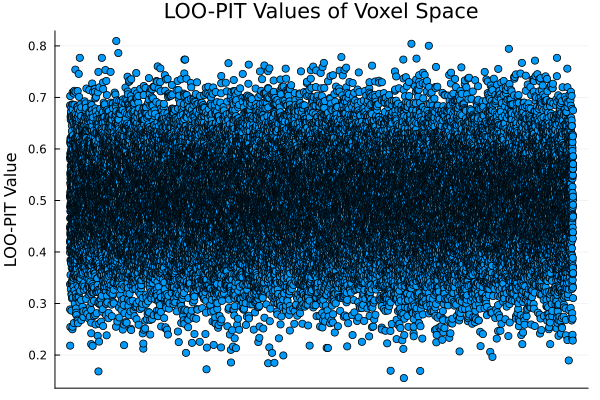

In [44]:
Plots.scatter(vec(PIT_Values), legend=false, xticks=false, ylabel="LOO-PIT Value", title = "LOO-PIT Values of Voxel Space")

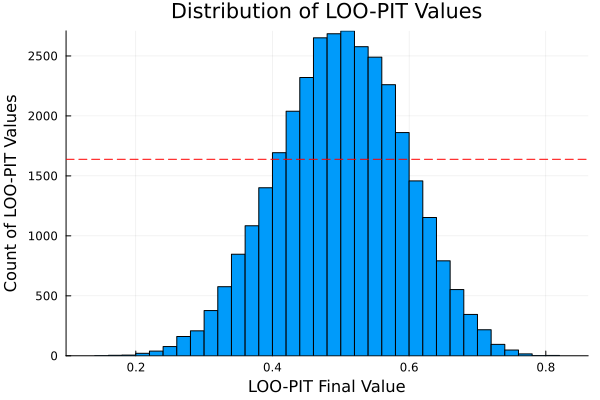

In [45]:
LOO_PIT_Plot = Plots.histogram(vec(PIT_Values), bins = 30, legend=false, ylabel="Count of LOO-PIT Values", xlabel="LOO-PIT Final Value", title="Distribution of LOO-PIT Values")
hline!([length(PIT_Values) / 20], color=:red, linestyle=:dash)

In [46]:
Plots.savefig(LOO_PIT_Plot, "LOOPIT_Results/LOOPIT_Fixed_ICs.png")
Plots.savefig(psis_plot, "LOOPIT_Results/PSIS_Fixed_ICs.png")

"/Users/ethansmith/Desktop/Waterloo/Masters/LOO_PIT_Manual/Field_Level_Data/LOOPIT_Results/PSIS_Fixed_ICs.png"

### Comparing the Voxel Posterior Predictive Distribution to the Data Distribution

##### First Voxel Only

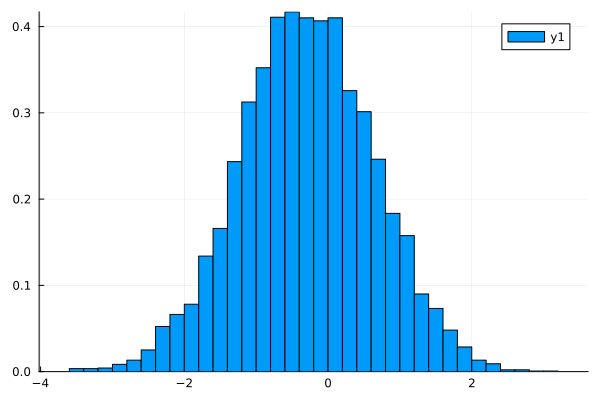

In [47]:
residuals = Vector{Float64}()
for n in 1:7168
    new_residual = (obs[1,1,1] - full_mean_data[1,1,1][n]) / sqrt(full_var_data[1,1,1][n])
    append!(residuals, new_residual)
end
histogram(residuals, normalize=:pdf)

##### All Voxels Together

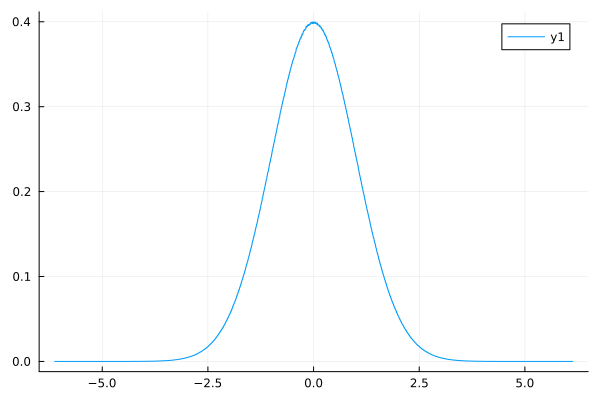

In [48]:
full_residuals = Vector{Float64}()
for n in 1:7168
    for i in 1:32
        for j in 1:32
            for k in 1:32
                new_residual = (obs[i,j,k] - full_mean_data[i,j,k][n]) / sqrt(full_var_data[i,j,k][n])
                append!(full_residuals, new_residual)
            end
        end
    end
end
histogram(full_residuals, normalize=:pdf)

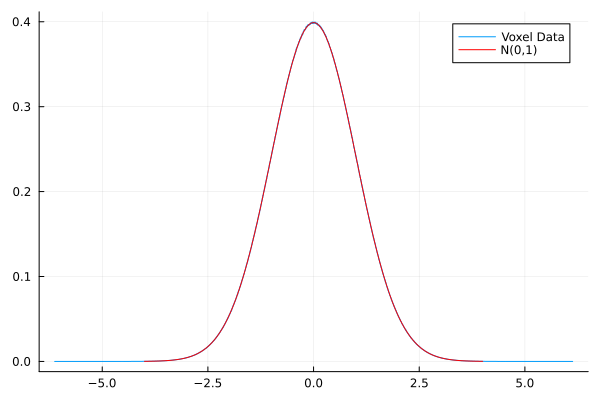

In [49]:
histogram(full_residuals, normalize=:pdf, label="Voxel Data")

x = range(-4, 4, length=1000)
plot!(
    x,
    pdf.(Normal(0,1), x),
    lw=1,
    color=:red,
    label="N(0,1)"
)